# Escenarios sintéticos de los ETF: planes 2, 3 y 4

Lee los CSV que escribe `python -m uvr_loan.synthetic` en `results/synthetic/`: `summary.csv`, `fan.csv`, y para el camino de ejemplo `prices.csv` y `<escenario>/<plan>.csv`.

Solo cambian los precios de los ETF desde t0; la UVR, las tasas de CDT, el FIC y los pagos son los históricos. Cada ETF sigue, desde su precio real en t0 (t = m / 12 años):

log P_m = log P_0 + drift · t + amplitud · sin(2π m / periodo) + σ · W_m (+ log(1 − caída) desde el mes de la caída)

con W un movimiento browniano mensual. Cada escenario tiene `n_paths` caminos aleatorios de una misma semilla (`seed`): la misma semilla da los mismos resultados, y el camino j usa los mismos números aleatorios en todos los escenarios. La volatilidad de cada ETF sigue a los precios simulados. Los parámetros están en `synthetic_etfs` de `config/assumptions.yaml`.

El plan 2 no tiene ETF: su resultado es el mismo en todos los escenarios y caminos.

1. **Distribución de la riqueza neta final** de los planes 3 y 4 en cada escenario (percentiles 10, 50 y 90), con el plan 2 como referencia.
2. **Riqueza neta en el tiempo:** banda entre los percentiles 10 y 90, y la mediana.
3. **Tabla resumen.**
4. **Un camino de ejemplo** (camino 0) por escenario, mes a mes.

In [14]:
import matplotlib.pyplot as plt
import pandas as pd

from uvr_loan.cashflows import decision_months
from uvr_loan.config import SYNTHETIC_DIR, load_assumptions

cfg = load_assumptions()
reviews = decision_months(cfg["backtest"])
ETFS = list(cfg["data"]["etfs"])
SCENARIOS = list(cfg["synthetic_etfs"]["scenarios"])
PLANS = {
    "cdt_ladder": "Plan 2 · escalera de CDT",
    "ldi": "Plan 3 · LDI (CDT + ETF)",
    "ratchet_ldi": "Plan 4 · LDI con trinquete (TIPP)",
}
# Paleta categórica de referencia (orden fijo): azul, naranja, aguamarina.
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
MUTED = "#6b6a63"

summary = pd.read_csv(SYNTHETIC_DIR / "summary.csv")
fan = pd.read_csv(SYNTHETIC_DIR / "fan.csv")
n_paths = cfg["synthetic_etfs"]["n_paths"]
prices = pd.read_csv(SYNTHETIC_DIR / "prices.csv")
runs = {
    (s, p): pd.read_csv(SYNTHETIC_DIR / s / f"{p}.csv").set_index("month")
    for s in SCENARIOS
    for p in PLANS
}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3dd", "grid.linewidth": 0.6, "lines.linewidth": 2})

## 1. Distribución de la riqueza neta final

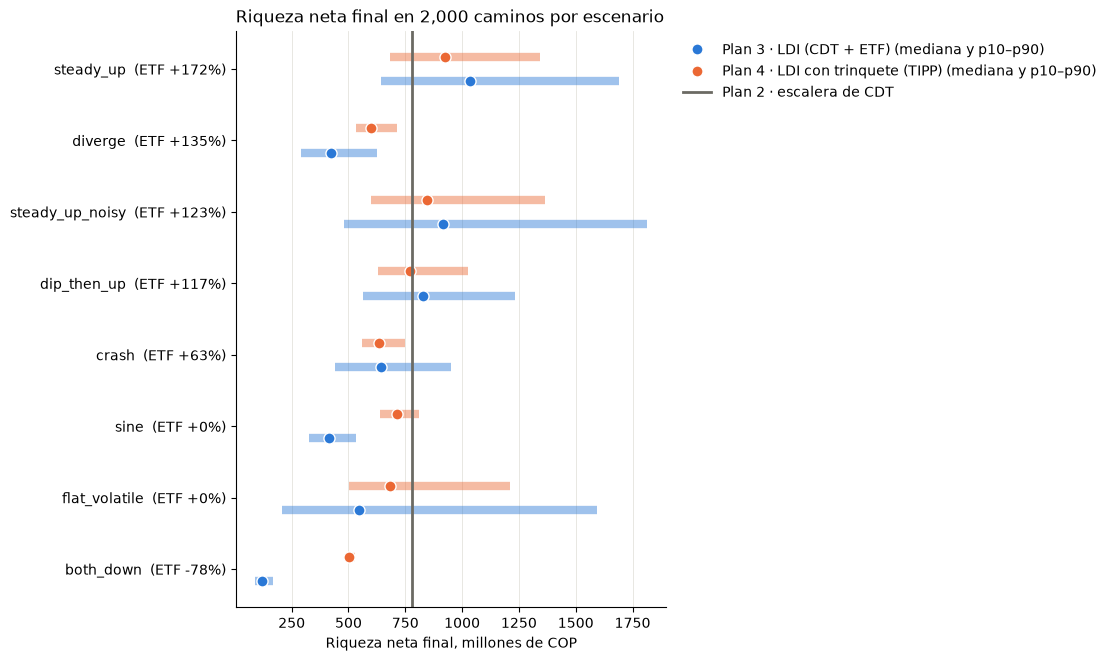

In [15]:
# Riqueza neta final: percentiles 10 a 90 (barra) y mediana (punto). Escenarios ordenados por el
# crecimiento de los ETF sin ruido; la línea gris vertical es el plan 2, igual en todos los escenarios.
order = summary.drop_duplicates("scenario").sort_values("etf_median_growth")["scenario"].tolist()
growth = summary.drop_duplicates("scenario").set_index("scenario")["etf_median_growth"]
fig, ax = plt.subplots(figsize=(11, 6.5), layout="constrained")
for offset, plan, color in [(-0.17, "ldi", COLORS[0]), (0.17, "ratchet_ldi", COLORS[1])]:
    rows = summary[summary["plan"] == plan].set_index("scenario").loc[order]
    y = [i + offset for i in range(len(order))]
    ax.hlines(y, rows["wealth_p10"] / 1e6, rows["wealth_p90"] / 1e6, color=color, linewidth=6, alpha=0.45)
    ax.plot(rows["wealth_p50"] / 1e6, y, "o", color=color, markersize=8, markeredgecolor="white",
            label=f"{PLANS[plan]} (mediana y p10–p90)")
plan2 = summary.loc[summary["plan"] == "cdt_ladder", "wealth_p50"].iloc[0] / 1e6
ax.axvline(plan2, color=MUTED, linewidth=2, label=PLANS["cdt_ladder"])
ax.set_yticks(range(len(order)), [f"{s}  (ETF {growth[s]:+.0%})" for s in order])
ax.set_xlabel("Riqueza neta final, millones de COP")
ax.set_title(f"Riqueza neta final en {n_paths:,} caminos por escenario", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

## 2. Riqueza neta en el tiempo

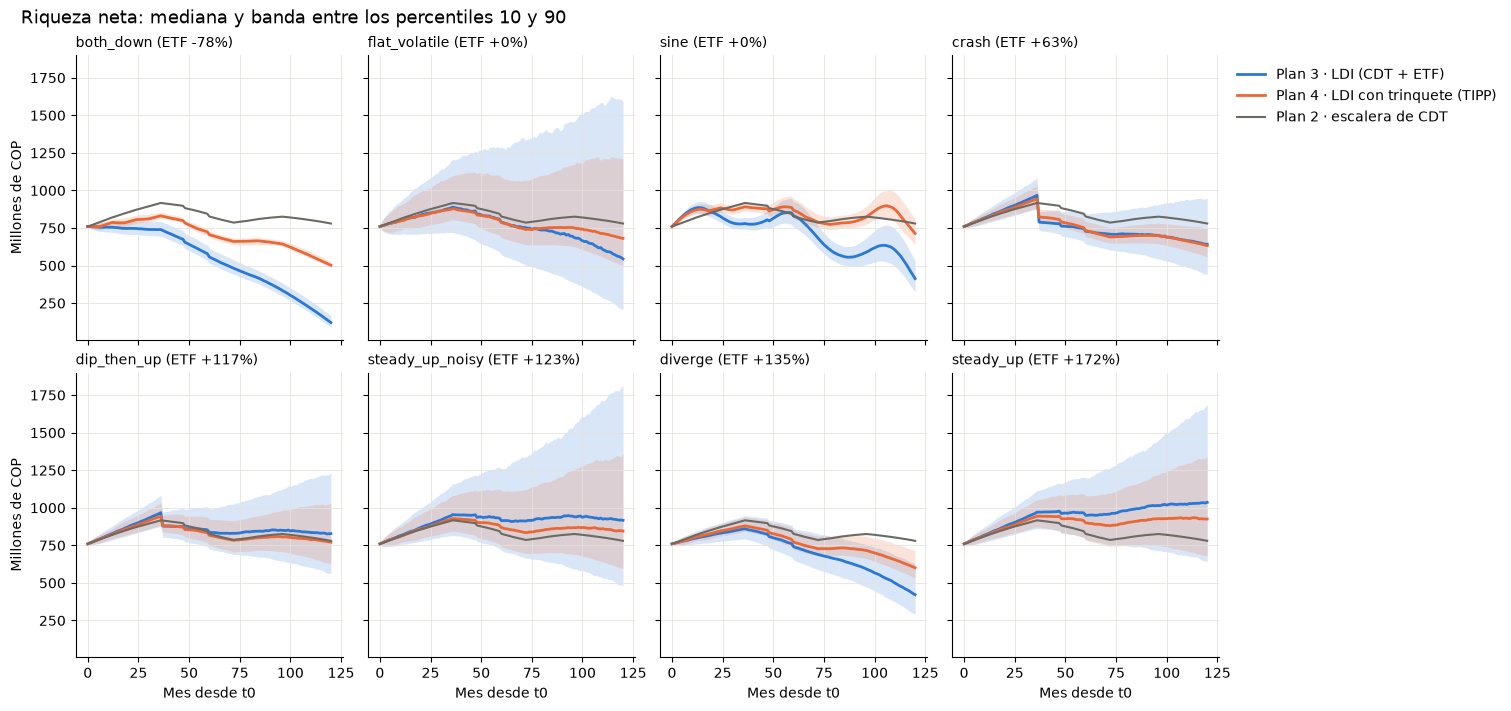

In [16]:
# Riqueza neta en el tiempo: banda p10–p90 y mediana de los planes 3 y 4; el plan 2 en gris.
fig, axes = plt.subplots(2, 4, figsize=(15, 7), sharex=True, sharey=True, layout="constrained")
for ax, scenario in zip(axes.flat, order, strict=True):
    f = fan[fan["scenario"] == scenario]
    for plan, color in [("ldi", COLORS[0]), ("ratchet_ldi", COLORS[1])]:
        g = f[f["plan"] == plan]
        ax.fill_between(g["month"], g["p10"] / 1e6, g["p90"] / 1e6, color=color, alpha=0.18, linewidth=0)
        ax.plot(g["month"], g["p50"] / 1e6, color=color, label=PLANS[plan])
    g = f[f["plan"] == "cdt_ladder"]
    ax.plot(g["month"], g["p50"] / 1e6, color=MUTED, linewidth=1.5, label=PLANS["cdt_ladder"])
    ax.set_title(f"{scenario} (ETF {growth[scenario]:+.0%})", loc="left", fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel("Millones de COP")
for ax in axes[1, :]:
    ax.set_xlabel("Mes desde t0")
axes[0, -1].legend(frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1))
fig.suptitle("Riqueza neta: mediana y banda entre los percentiles 10 y 90", x=0.01, ha="left", fontsize=13)
plt.show()

## 3. Tabla resumen

In [17]:
# Riqueza en millones de COP. beats_plan3: fracción de caminos en que el plan termina con más riqueza
# neta que el plan 3 en el mismo camino. shortfall_share: fracción de caminos con algún mes de déficit.
shown = summary.set_index(["scenario", "plan"]).loc[order]
money = [c for c in shown.columns if c.startswith("wealth_")]
shown[money] = shown[money] / 1e6
shown.round(3)

etf_median_growth  wealth_mean  wealth_p10  \
scenario        plan                                                      
both_down       cdt_ladder              -0.777      780.063     780.063   
                ldi                     -0.777      126.046      89.894   
                ratchet_ldi             -0.777      505.953     487.668   
flat_volatile   cdt_ladder               0.000      780.063     780.063   
                ldi                      0.000      785.721     205.601   
                ratchet_ldi              0.000      798.363     500.815   
sine            cdt_ladder               0.000      780.063     780.063   
                ldi                      0.000      421.956     324.299   
                ratchet_ldi              0.000      720.831     638.887   
crash           cdt_ladder               0.631      780.063     780.063   
                ldi                      0.631      673.563     441.038   
                ratchet_ldi              0.631      645.012     559.912   
dip_then_up     cdt_ladder               1.175      780.063     780.063   
                ldi                      1.175      869.093     562.158   
                ratchet_ldi              1.175      807.380     628.709   
steady_up_noisy cdt_ladder               1.226      780.063     780.063   
                ldi                      1.226     1060.310     480.447   
                ratchet_ldi              1.226      932.378     597.419   
diverge         cdt_ladder               1.352      780.063     780.063   
                ldi                      1.352      443.997     290.975   
                ratchet_ldi              1.352      615.769     533.817   
steady_up       cdt_ladder               1.718      780.063     780.063   
                ldi                      1.718     1114.160     643.057   
                ratchet_ldi              1.718      979.122     681.338   

                             wealth_p50  wealth_p90  drawdown_mean  \
scenario        plan                                                 
both_down       cdt_ladder      780.063     780.063          0.000   
                ldi             121.064     169.515          0.166   
                ratchet_ldi     502.265     528.972          0.034   
flat_volatile   cdt_ladder      780.063     780.063          0.000   
                ldi             544.532    1594.136          0.325   
                ratchet_ldi     681.162    1209.988          0.129   
sine            cdt_ladder      780.063     780.063          0.000   
                ldi             413.289     532.829          0.219   
                ratchet_ldi     714.173     812.352          0.109   
crash           cdt_ladder      780.063     780.063          0.000   
                ldi             641.872     952.047          0.189   
                ratchet_ldi     633.034     748.352          0.126   
dip_then_up     cdt_ladder      780.063     780.063          0.000   
                ldi             828.130    1232.400          0.108   
                ratchet_ldi     771.029    1025.219          0.068   
steady_up_noisy cdt_ladder      780.063     780.063          0.000   
                ldi             916.667    1813.076          0.183   
                ratchet_ldi     844.906    1362.760          0.091   
diverge         cdt_ladder      780.063     780.063          0.000   
                ldi             421.599     624.433          0.115   
                ratchet_ldi     600.802     714.803          0.044   
steady_up       cdt_ladder      780.063     780.063          0.000   
                ldi            1036.423    1688.649          0.114   
                ratchet_ldi     925.149    1341.972          0.064   

                             drawdown_p90  shortfall_share  beats_plan3  
scenario        plan                                                     
both_down       cdt_ladder          0.000            1.000        1.000  
                ldi                

## 4. Un camino de ejemplo por escenario

El camino 0 de cada escenario, mes a mes. Es un solo camino: sirve para ver cómo decide cada plan, no para comparar resultados (para eso, las secciones 1 a 3).

In [18]:
def plot_scenario(scenario):
    fig = plt.figure(figsize=(13, 10), layout="constrained")
    grid = fig.add_gridspec(3, 2)
    ax_price = fig.add_subplot(grid[0, :])
    ax3, ax4 = fig.add_subplot(grid[1, 0]), None
    ax4 = fig.add_subplot(grid[1, 1], sharey=ax3)
    ax_wealth = fig.add_subplot(grid[2, :])
    fig.suptitle(f"Escenario: {scenario} · camino de ejemplo (camino 0)", fontsize=14, x=0.01, ha="left")

    # Precios (índice 100 en t0)
    p = prices[prices["scenario"] == scenario].set_index("month")
    for i, name in enumerate(ETFS):
        price = p[f"{name}_price_cop"]
        ax_price.plot(price.index, 100 * price / price.iloc[0], color=COLORS[i], label=name)
    for m in reviews:
        ax_price.axvline(m, color=MUTED, linestyle=":", linewidth=0.8)
    ax_price.set_ylabel("Índice (t0 = 100)")
    ax_price.set_title("Precios de los ETF en COP", loc="left")
    ax_price.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))

    # Composición de los planes 3 y 4
    for ax, plan in [(ax3, "ldi"), (ax4, "ratchet_ldi")]:
        r = runs[(scenario, plan)]
        for column, label, color in zip(["fic_cop", "etf_cop", "cdt_cop"], ["FIC", "ETF", "CDT"], COLORS, strict=True):
            ax.plot(r.index, r[column] / 1e6, color=color, label=label)
        ax.set_title(PLANS[plan], loc="left")
        ax.set_ylabel("Millones de COP")
    ax4.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))

    # Riqueza neta de los planes 2, 3 y 4
    for (plan, label), color in zip(PLANS.items(), [MUTED, COLORS[0], COLORS[1]], strict=True):
        r = runs[(scenario, plan)]
        ax_wealth.plot(r.index, r["wealth_net_cop"] / 1e6, color=color, label=label)
    ax_wealth.set_title("Riqueza neta", loc="left")
    ax_wealth.set_ylabel("Millones de COP")
    ax_wealth.set_xlabel("Mes desde t0")
    ax_wealth.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
    plt.show()

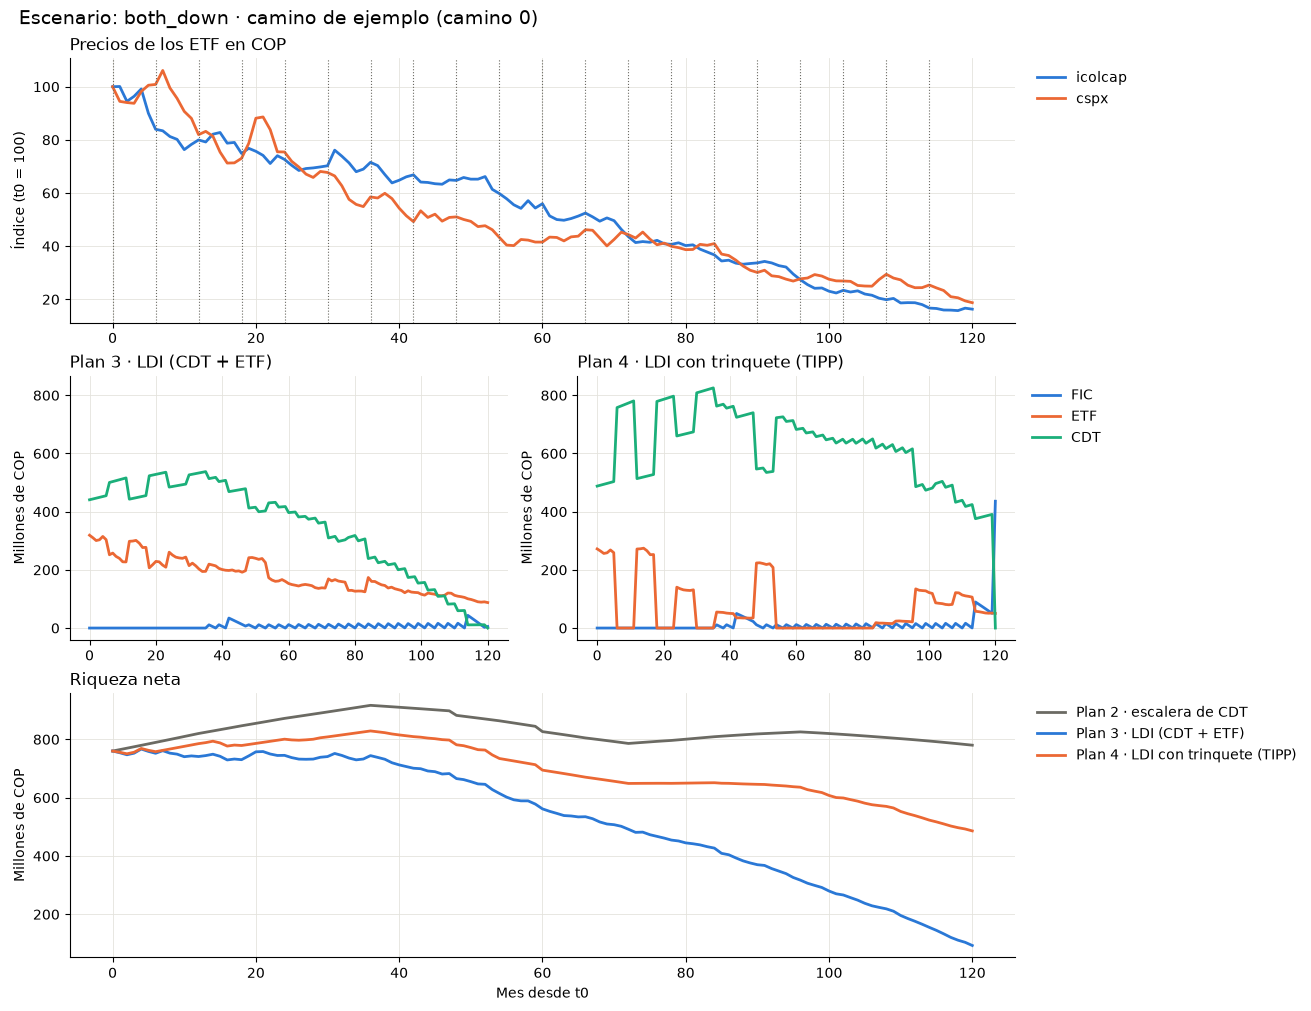

In [19]:
plot_scenario("both_down")

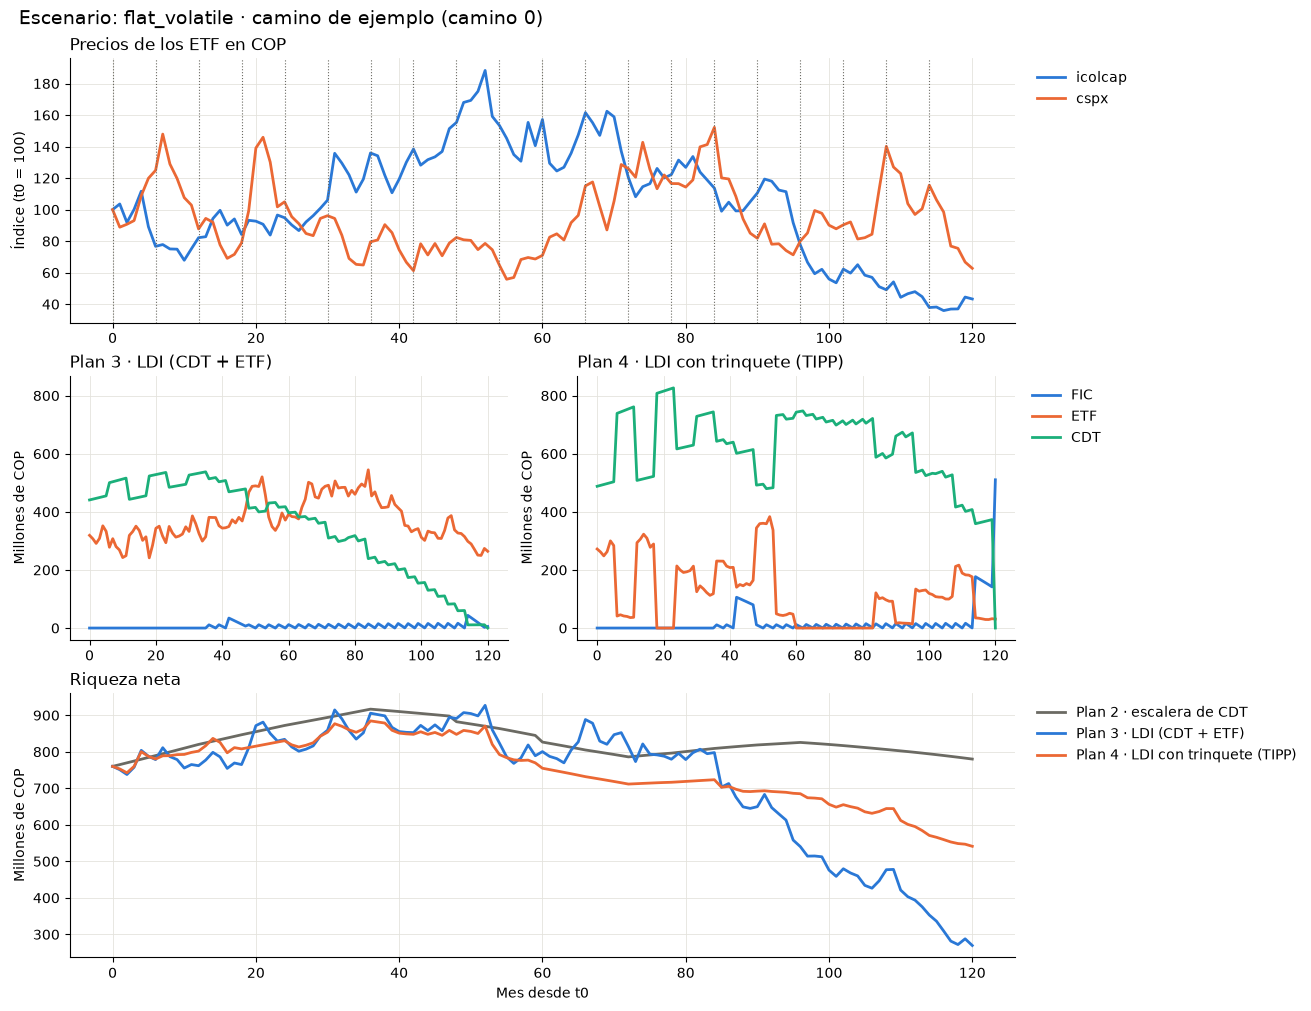

In [20]:
plot_scenario("flat_volatile")

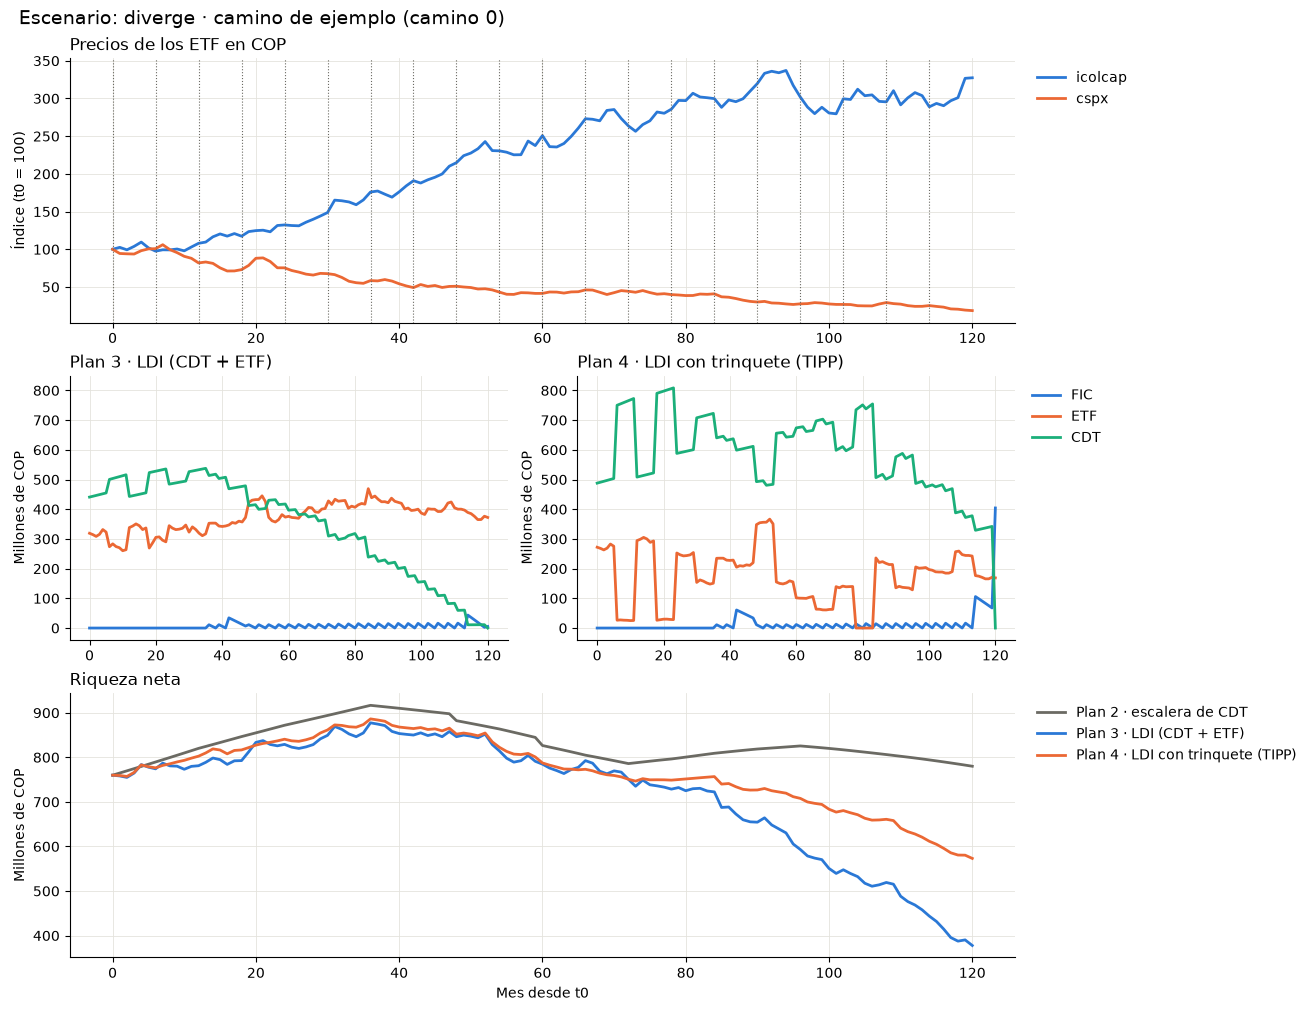

In [21]:
plot_scenario("diverge")

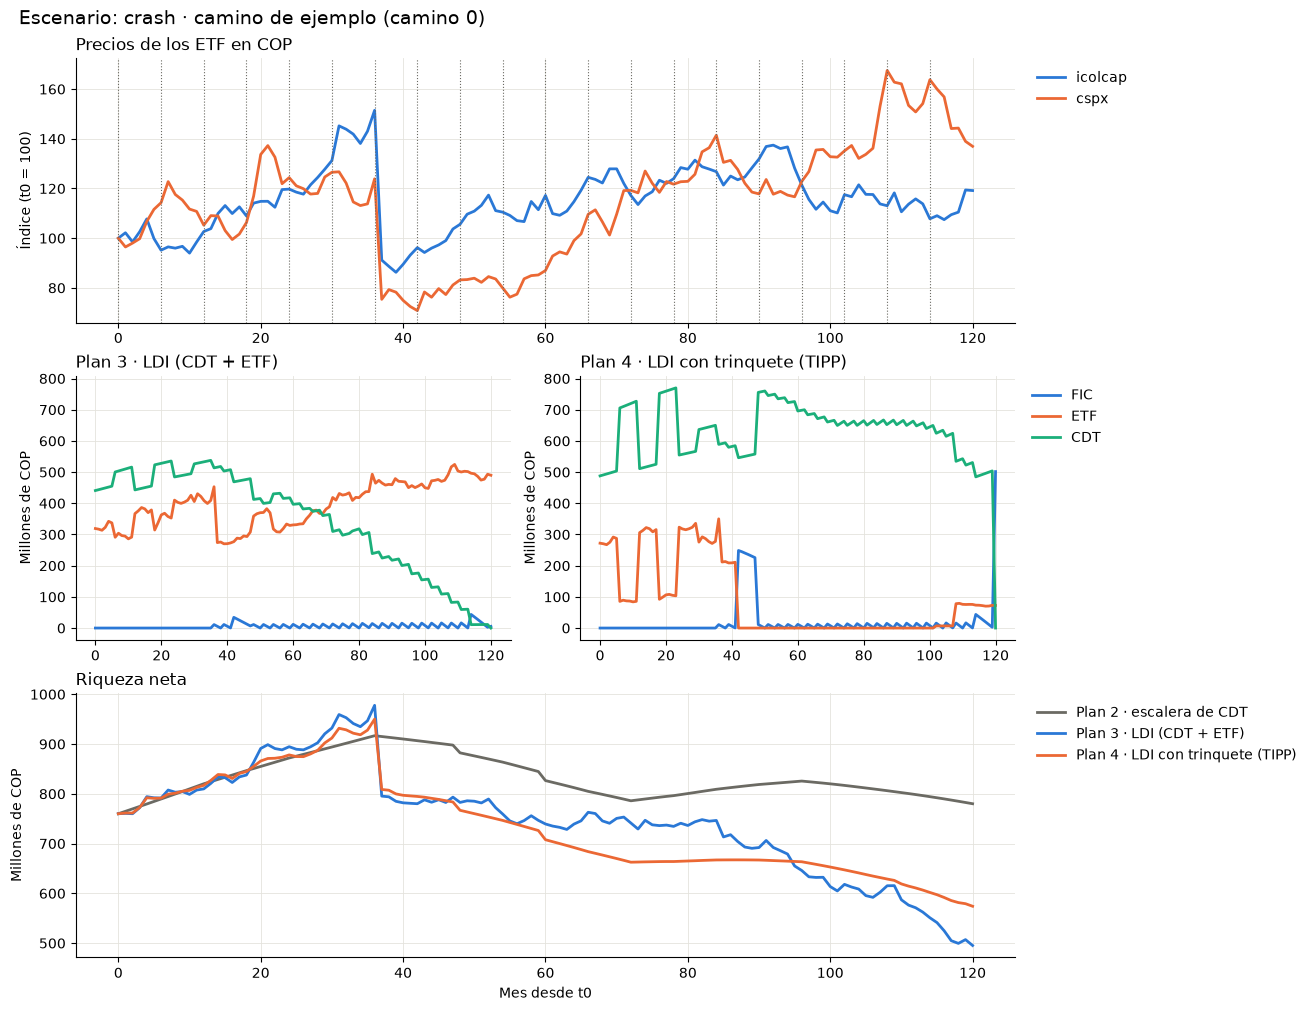

In [22]:
plot_scenario("crash")

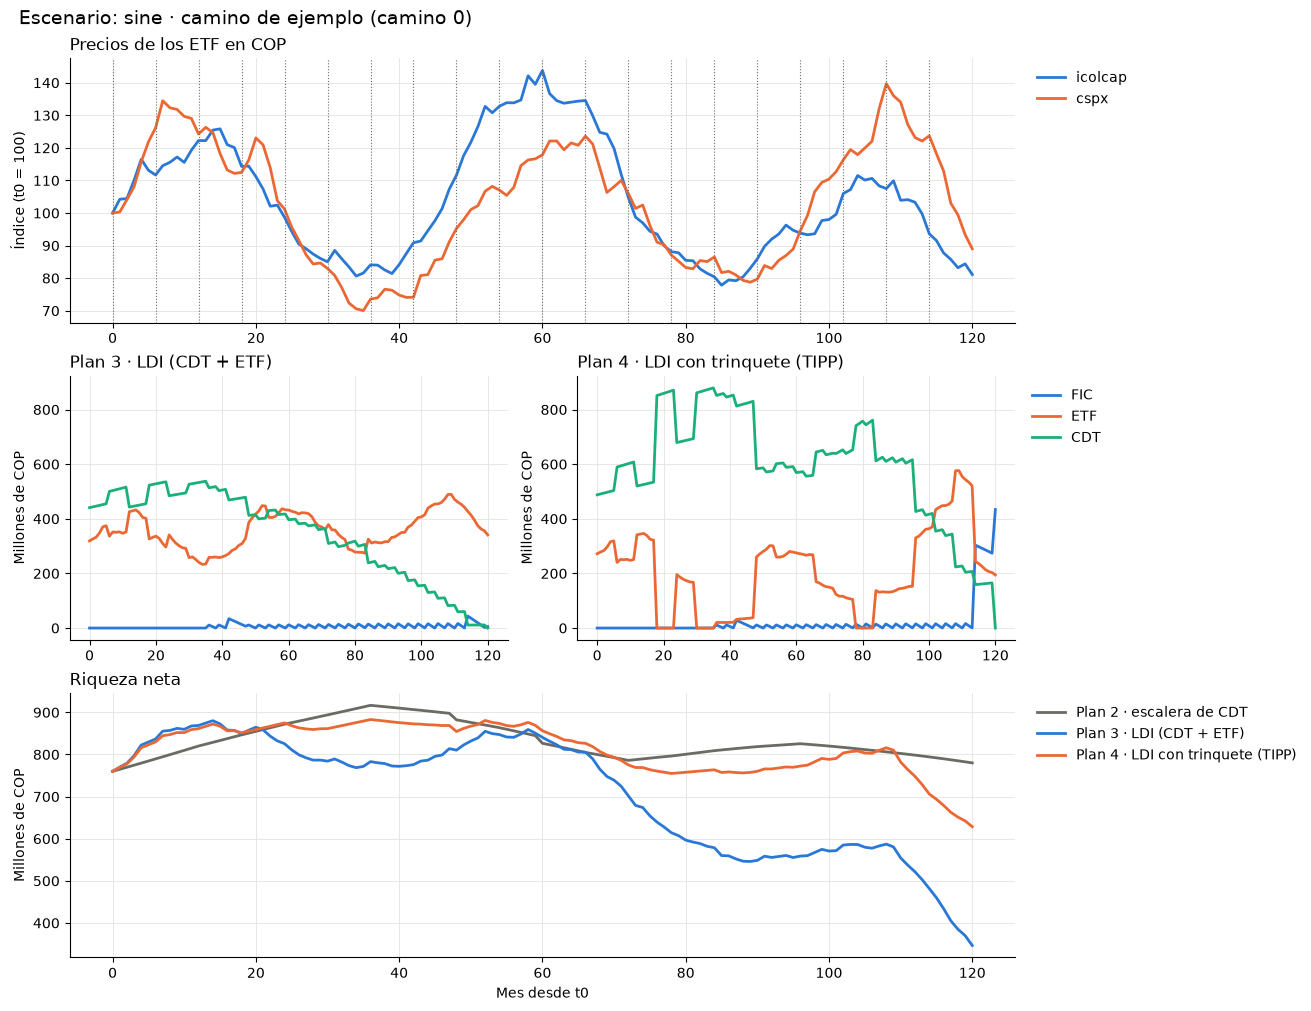

In [23]:
plot_scenario("sine")

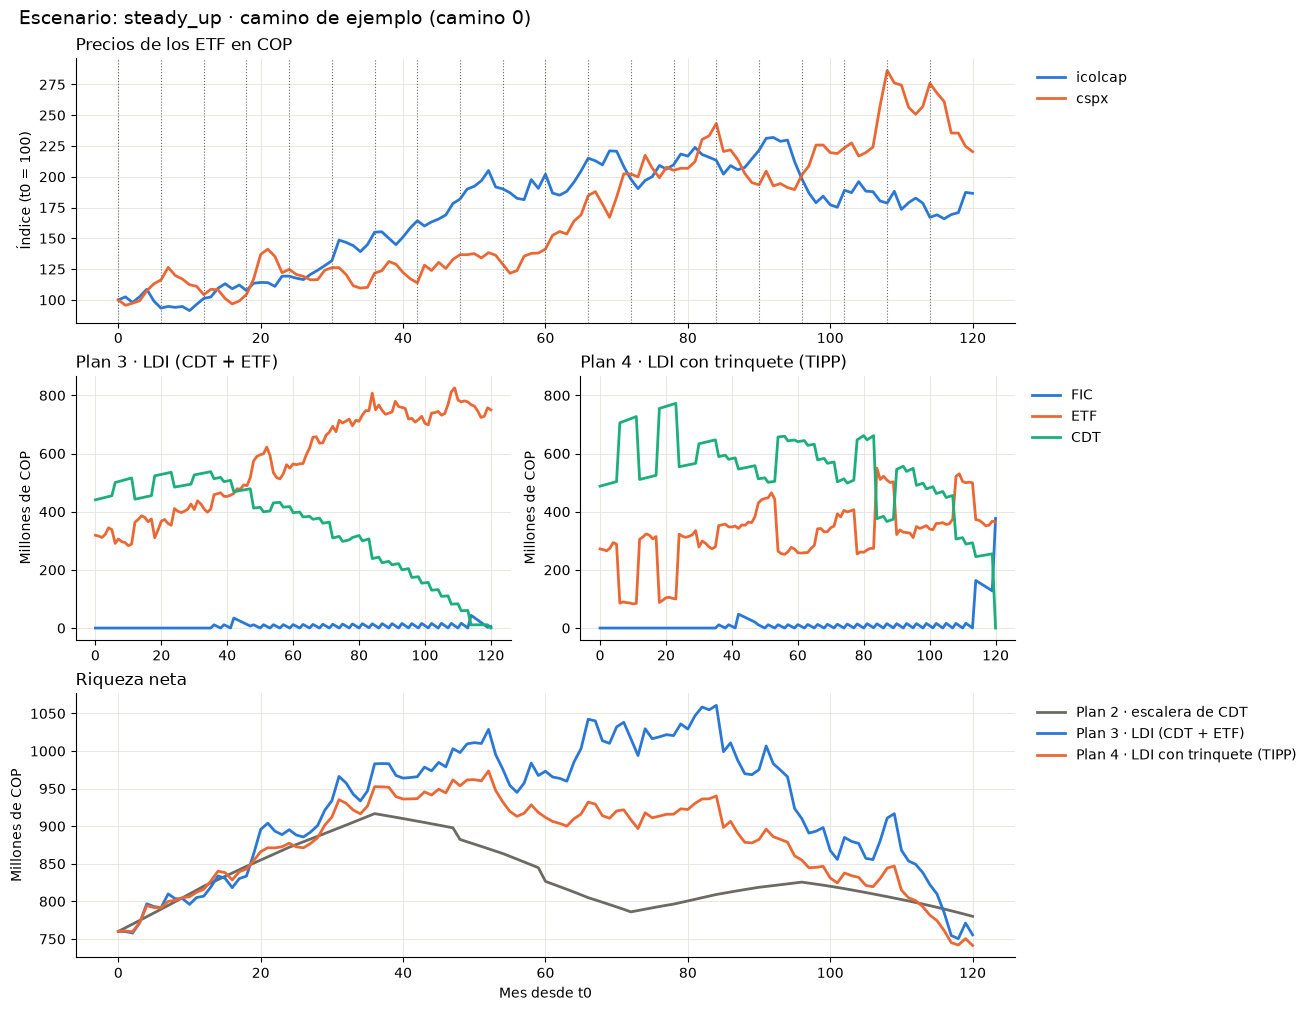

In [24]:
plot_scenario("steady_up")

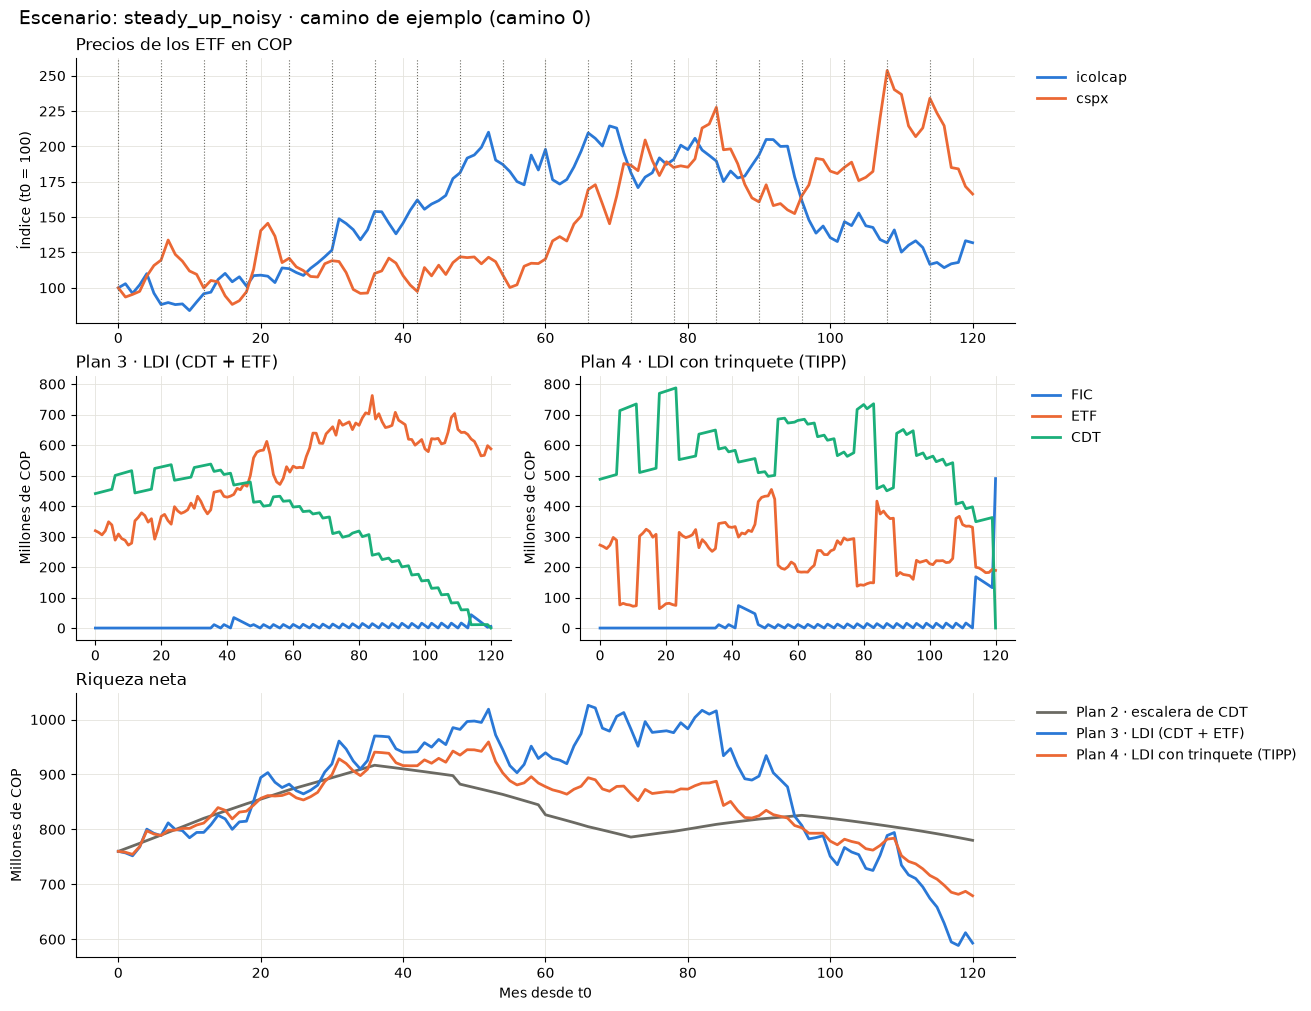

In [25]:
plot_scenario("steady_up_noisy")

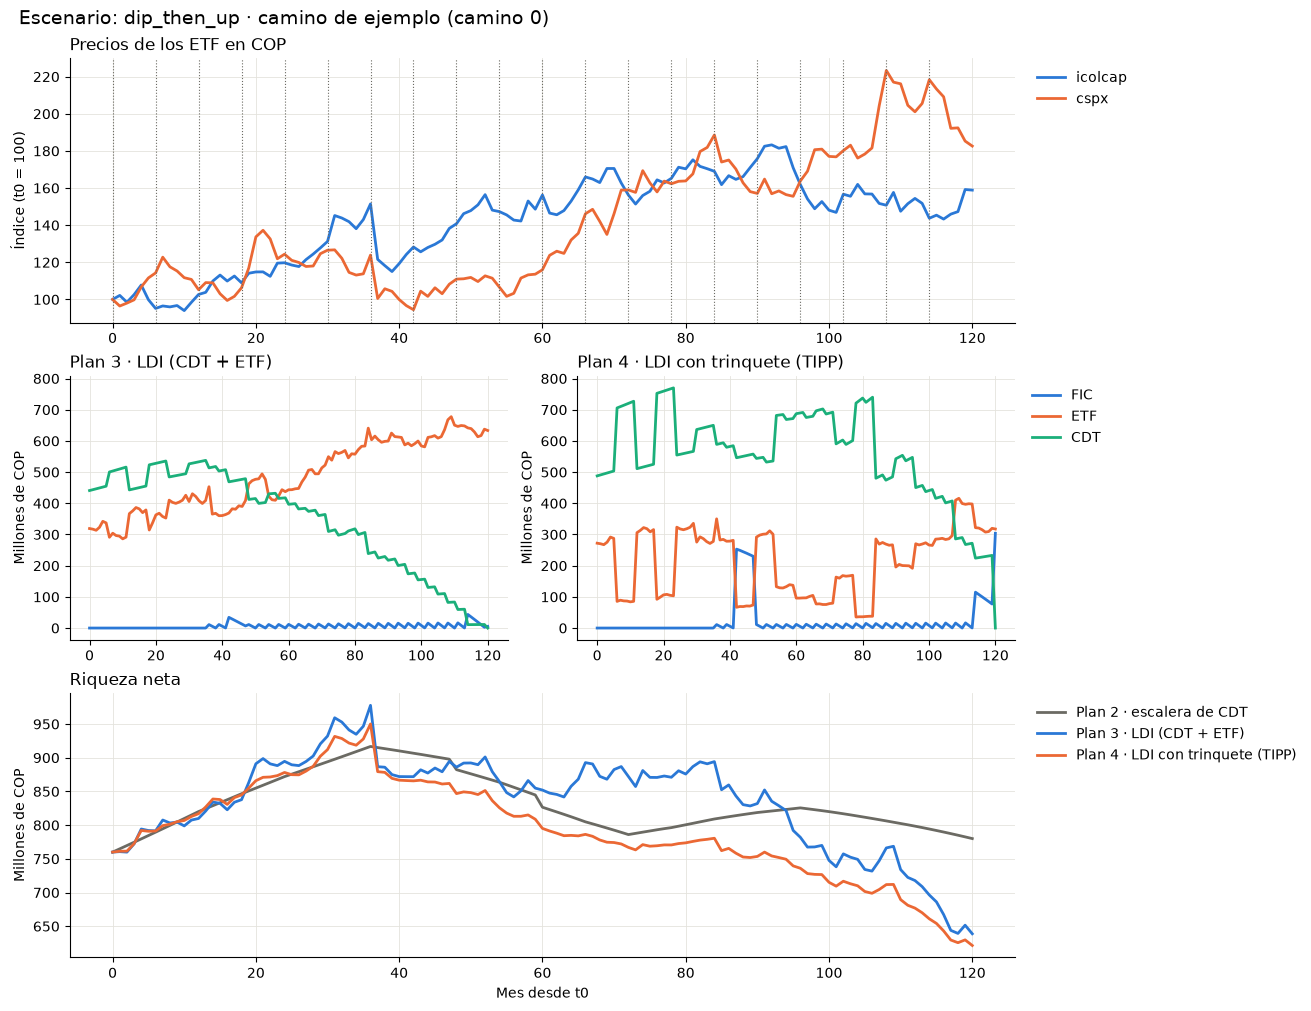

In [26]:
plot_scenario("dip_then_up")